
--- FIRST 5 ROWS ---
   Transaction_ID  Customer_ID State  Age Shop_Category  Sales Gender  \
0               1         1234    MP   10       Grocery     10      M   
1               2         1235    UP   21         Dairy     30      F   
2               3         1236    AP   23          Deli     23      F   
3               4         1237    RP   25          Meat     21      F   
4               5         1238    DP   27       Clothes     90      F   

   Items_in_basket  
0                2  
1                3  
2                4  
3                4  
4                3  

--- DATA SHAPE ---
(312, 8)

--- DATA INFORMATION ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Transaction_ID   312 non-null    int64 
 1   Customer_ID      312 non-null    int64 
 2   State            312 non-null    object
 3   Age              312 non

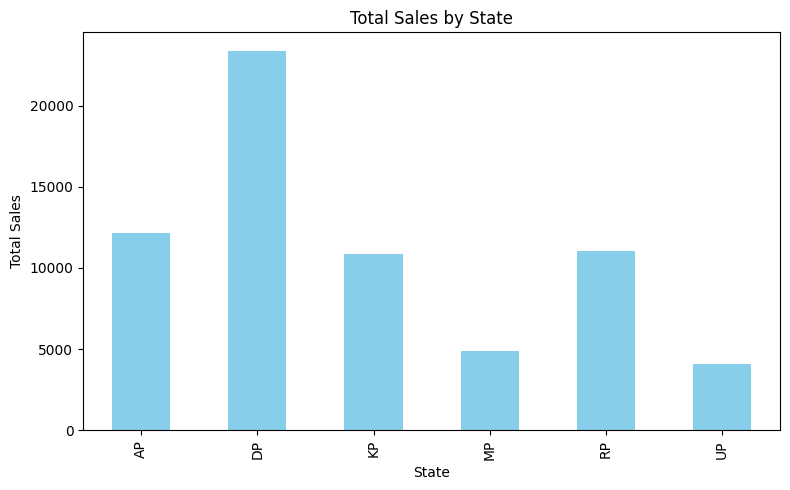

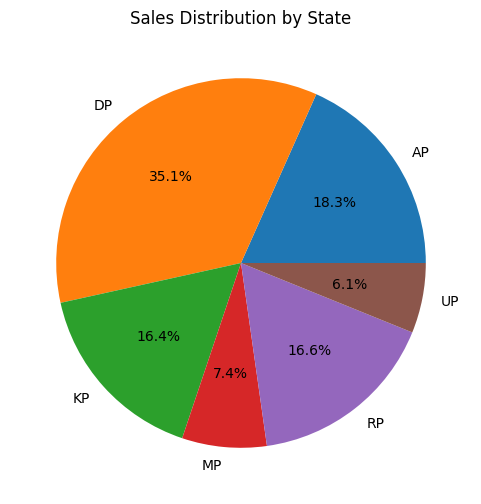


--- TOP PERFORMING REGION ---
Region: DP
Highest Sales: 23346

--- SALES RANKING ---
State
DP    23346
AP    12176
RP    11049
KP    10887
MP     4916
UP     4072
Name: Sales, dtype: int64

--- SALES BY STATE AND SHOP CATEGORY ---
State  Shop_Category
AP     Clothes          2127
       Dairy            1197
       Deli             1303
       Electronics      3818
       Grocery           823
       Meat             2908
DP     Clothes          7133
       Dairy            6027
       Deli             1723
       Electronics      4645
       Grocery          1736
       Meat             2082
KP     Clothes          3581
       Dairy             630
       Deli             2595
       Electronics      2742
       Grocery            54
       Meat             1285
MP     Clothes           711
       Deli             1144
       Electronics       696
       Grocery           950
       Meat             1415
RP     Clothes          2167
       Dairy              74
       Deli           

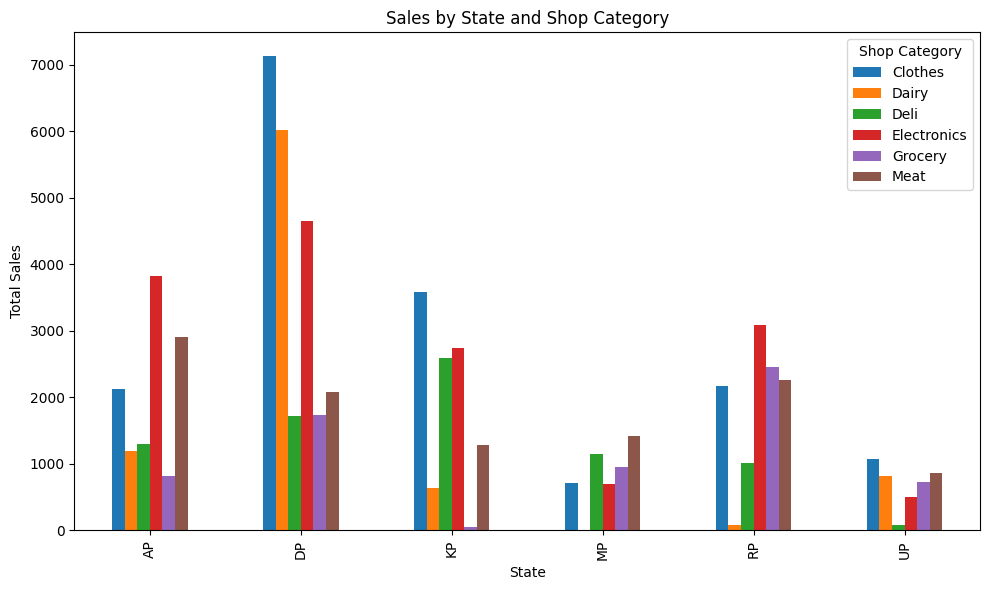

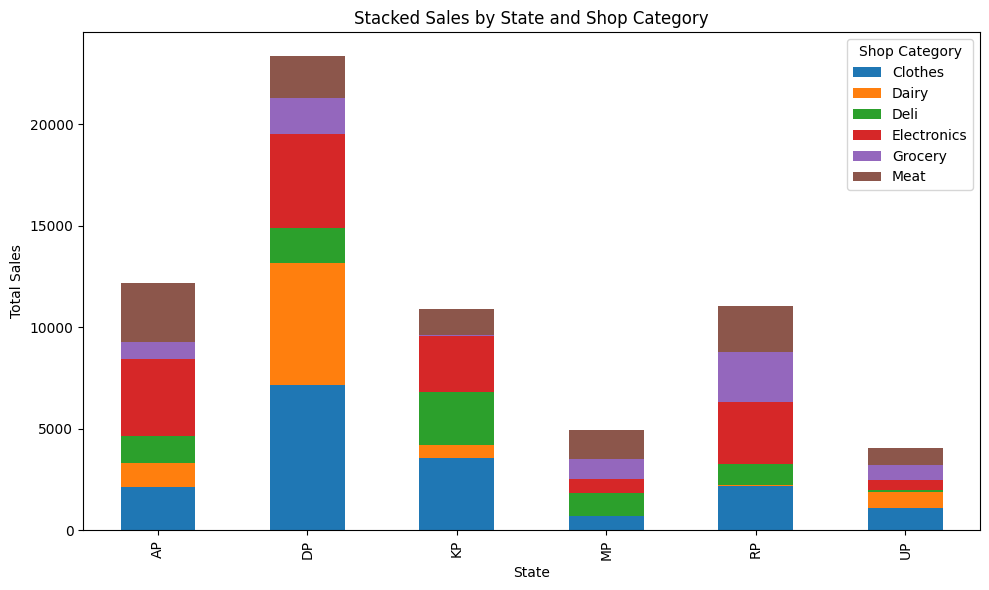


Data Aggregation Completed Successfully!


In [1]:
# 1. Import Libraries
import pandas as pd
import matplotlib.pyplot as plt

# 2. Load Dataset
df = pd.read_csv("Retail_Sales_Data.csv")

print("\n--- FIRST 5 ROWS ---")
print(df.head())

print("\n--- DATA SHAPE ---")
print(df.shape)

print("\n--- DATA INFORMATION ---")
df.info()

print("\n--- DATA DESCRIPTION ---")
print(df.describe())

print("\n--- COLUMN NAMES ---")
print(df.columns.tolist())

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

# 3. Identify Relevant Variables
region_col = "State"
sales_col = "Sales"
category_col = "Shop_Category"

# 4. Total Sales by Region
sales_by_region = df.groupby(region_col)[sales_col].sum()

print("\n--- TOTAL SALES BY REGION ---")
print(sales_by_region)

# 5. Bar Chart: Sales by Region
sales_by_region.plot(
    kind="bar",
    figsize=(8, 5),
    color="skyblue"
)

plt.title("Total Sales by State")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

# Pie Chart: Sales Distribution
sales_by_region.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6)
)

plt.title("Sales Distribution by State")
plt.ylabel("")
plt.show()

# 6. Top Performing Region
top_region = sales_by_region.idxmax()

print("\n--- TOP PERFORMING REGION ---")
print("Region:", top_region)
print("Highest Sales:", sales_by_region.max())

# Display regions in descending order
print("\n--- SALES RANKING ---")
print(sales_by_region.sort_values(ascending=False))

# 7. Sales by Region and Product Category
region_category_sales = df.groupby(
    [region_col, category_col]
)[sales_col].sum()

print("\n--- SALES BY STATE AND SHOP CATEGORY ---")
print(region_category_sales)

# Convert into a table
table = region_category_sales.unstack(fill_value=0)

print("\n--- SALES TABLE ---")
print(table)

# 8. Grouped Bar Chart
table.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sales by State and Shop Category")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.legend(title="Shop Category")
plt.tight_layout()
plt.show()

# Stacked Bar Chart
table.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Stacked Sales by State and Shop Category")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.legend(title="Shop Category")
plt.tight_layout()
plt.show()

print("\nData Aggregation Completed Successfully!")